# Reduced-electrode seizure detection on CHB-MIT — results walkthrough

This notebook reads the artefacts produced by the scripts in `scripts/`; it does
not recompute them. To regenerate everything from scratch:

```
python scripts/01_inventory.py
python scripts/02_download.py
python scripts/04_extract_and_prune.py --keep chb01
python scripts/06_experiments.py main
python scripts/06_experiments.py random
python scripts/07_report.py
python scripts/05_figures.py explore && python scripts/05_figures.py results
```

**What is being compared.** CHB-MIT channels such as `F7-T7` are *bipolar
differences between two electrodes*. A four-contact wearable mock-up gives two
bipolar channels; a two-contact one gives a single channel. These are
scalp-position proxies, not recordings from real glasses or earbuds.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from seizure_eeg.config import (DATA_ROOT, FIGURES_DIR, MONTAGES,
                                MONTAGE_CONTACTS, TABLES_DIR)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
print("repo:", ROOT)

repo: /home/user/forge_seizure_eeg


## 1. What is in the dataset

Parsed from the per-subject `chbXX-summary.txt` files, not inferred from
filenames. chb01 and chb21 are the **same person**, so the 24 cases are 23
people — they are kept in one cross-validation group.

In [2]:
inv = pd.read_csv(TABLES_DIR / "subject_inventory.csv")
print(f"{len(inv)} cases, {inv.n_seizures.sum()} annotated seizures, "
      f"{inv.ictal_seconds.sum()/3600:.1f} ictal hours")
display(inv[["case", "n_files_in_summary", "n_seizure_files", "n_seizures",
             "ictal_seconds"]].head(24))

24 cases, 198 annotated seizures, 3.2 ictal hours


,case,n_files_in_summary,n_seizure_files,n_seizures,ictal_seconds
0,chb01,42,7,7,442
1,chb02,36,3,3,172
2,chb03,38,7,7,402
3,chb04,42,3,4,378
4,chb05,39,5,5,558
5,chb06,18,7,10,153
6,chb07,19,3,3,325
7,chb08,20,5,5,919
8,chb09,19,3,4,276
9,chb10,25,7,7,447


## 2. The electrode configurations

Every configuration below is a list of **bipolar derivations**, with the
physical contacts each one would need.

In [3]:
rows = [{"configuration": m, "contacts": len(MONTAGE_CONTACTS[m]),
         "which contacts": ", ".join(MONTAGE_CONTACTS[m]),
         "bipolar channels": len(MONTAGES[m]),
         "derivations": ", ".join(MONTAGES[m])}
        for m in MONTAGES]
display(pd.DataFrame(rows))

,configuration,contacts,which contacts,bipolar channels,derivations
0,full_18_bipolar,19,"C3, C4, CZ, F3, F4, F7, F8, FP1, FP2, FZ, O1, ...",18,"FP1-F7, F7-T7, T7-P7, P7-O1, FP1-F3, F3-C3, C3..."
1,glasses_4_contacts,4,"F7, F8, FP1, FP2",2,"FP1-F7, FP2-F8"
2,temporal_4_contacts,4,"F7, F8, T7, T8",2,"F7-T7, F8-T8"
3,posterior_temporal_4_contacts,4,"P7, P8, T7, T8",2,"T7-P7, T8-P8"
4,lower_temporal_4_contacts,4,"FT10, FT9, T7, T8",2,"T7-FT9, FT10-T8"
5,left_temporal_2_contacts,2,"F7, T7",1,F7-T7
6,right_temporal_2_contacts,2,"F8, T8",1,F8-T8


## 3. Features from one recording

Features are computed **once for the union of every montage's channels**, so a
montage's design matrix is a column slice. That makes the comparison paired by
construction: identical recordings, identical windows, identical labels.

In [4]:
from seizure_eeg.dataset import (UNION_CHANNELS, available_montages,
                                 extract_recording, montage_matrix)
from seizure_eeg.summary import parse_summary

edf = DATA_ROOT / "chb01" / "chb01_03.edf"
if edf.exists():
    intervals = parse_summary(DATA_ROOT / "chb01" / "chb01-summary.txt")["chb01_03.edf"]
    X, Q, meta = extract_recording(edf, intervals)
    print("seizure intervals:", intervals)
    print("feature tensor (windows, channels, features):", X.shape)
    print("montages available in this recording:", available_montages(Q))
    for m in ["full_18_bipolar", "temporal_4_contacts", "left_temporal_2_contacts"]:
        d, usable, names = montage_matrix(X, Q, m)
        print(f"  {m:30s} design {d.shape}, usable windows {usable.sum()}")
    display(meta[meta.label == 1][["start_s", "stop_s", "ictal_overlap_s",
                                   "seizure_idx", "label"]])
else:
    print("raw chb01 EDFs not present - run scripts/02_download.py --cases chb01")

seizure intervals: [(2996, 3036)]
feature tensor (windows, channels, features): (360, 20, 14)
montages available in this recording: ['full_18_bipolar', 'glasses_4_contacts', 'temporal_4_contacts', 'posterior_temporal_4_contacts', 'lower_temporal_4_contacts', 'left_temporal_2_contacts', 'right_temporal_2_contacts']
  full_18_bipolar                design (360, 252), usable windows 360
  temporal_4_contacts            design (360, 28), usable windows 360
  left_temporal_2_contacts       design (360, 14), usable windows 360


,start_s,stop_s,ictal_overlap_s,seizure_idx,label
299,2990.0,3000.0,4.0,0,1
300,3000.0,3010.0,10.0,0,1
301,3010.0,3020.0,10.0,0,1
302,3020.0,3030.0,10.0,0,1
303,3030.0,3040.0,6.0,0,1


## 4. The same seizure through each electrode set

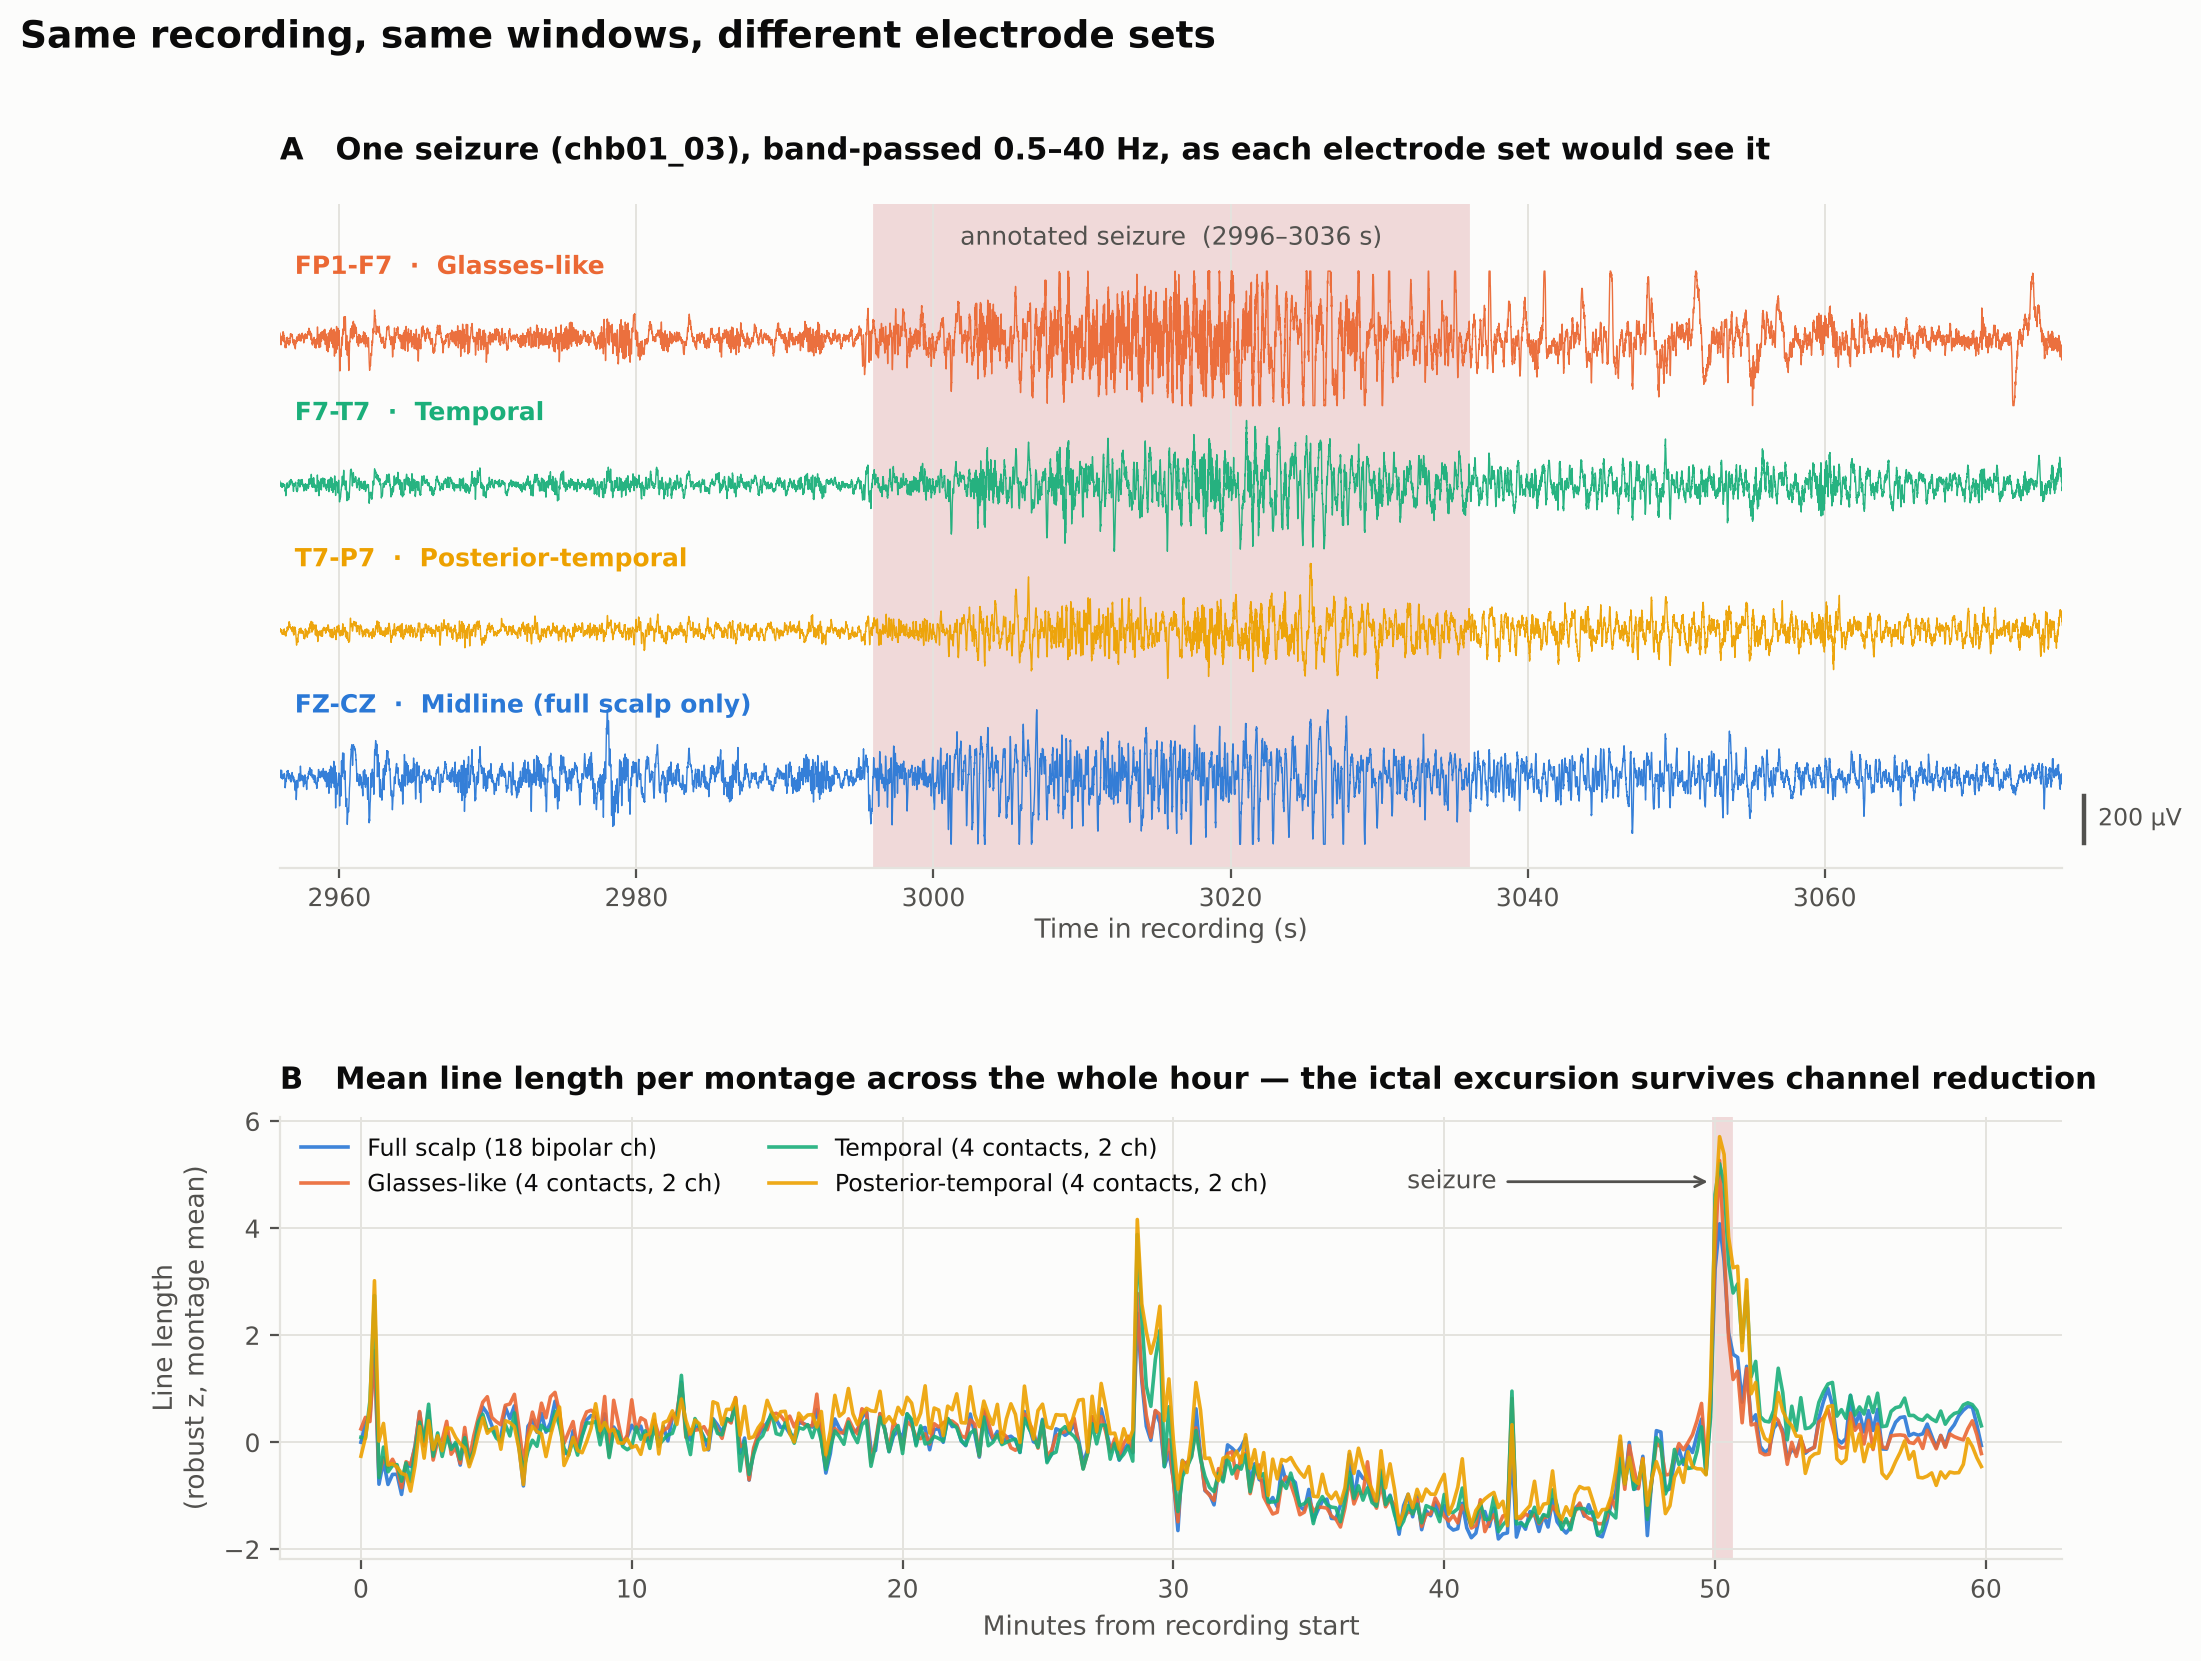

In [5]:
display(Image(filename=str(FIGURES_DIR / "fig1_exploratory_montages.png")))

## 5. Patient-disjoint benchmark

Shrinkage LDA, 5-fold `GroupKFold` over patients. Decision thresholds are fitted
on out-of-fold scores from the **training** patients and applied unchanged to
the held-out patients. Confidence intervals are percentile bootstraps over
patients.

In [6]:
sys.path.insert(0, str(ROOT / "scripts"))
from importlib import import_module
report = import_module("07_report")

folds = pd.read_csv(TABLES_DIR / "cv_folds_main.csv")
patients = pd.read_csv(TABLES_DIR / "cv_patients_main.csv")
summary = report.summary_table(patients, folds, target=6.0)
display(Markdown(report.to_markdown(summary, 6.0)))

| Configuration | Contacts | Bipolar ch | AUPRC [95% CI] | Seizure sensitivity @ 6 FA/h target | Achieved FA/h | Median latency | Seizures detected |
|---|---:|---:|---|---|---:|---:|---:|
| Full scalp (18 bipolar ch) | 19 | 18 | 0.209 [0.113–0.318] | 0.80 [0.68–0.90] | 9.6 | 18 s | 142/198 |
| Glasses-like (4 contacts, 2 ch) | 4 | 2 | 0.133 [0.069–0.211] | 0.73 [0.60–0.85] | 5.7 | 28 s | 118/198 |
| Temporal (4 contacts, 2 ch) | 4 | 2 | 0.170 [0.091–0.272] | 0.81 [0.68–0.92] | 5.3 | 20 s | 136/198 |
| Posterior-temporal (4 contacts, 2 ch) | 4 | 2 | 0.195 [0.112–0.301] | 0.80 [0.67–0.92] | 5.3 | 21 s | 142/198 |
| Left temporal (2 contacts, 1 ch) | 2 | 1 | 0.198 [0.114–0.299] | 0.78 [0.65–0.90] | 5.7 | 23 s | 134/198 |
| Right temporal (2 contacts, 1 ch) | 2 | 1 | 0.119 [0.068–0.181] | 0.77 [0.64–0.89] | 5.9 | 27 s | 138/198 |


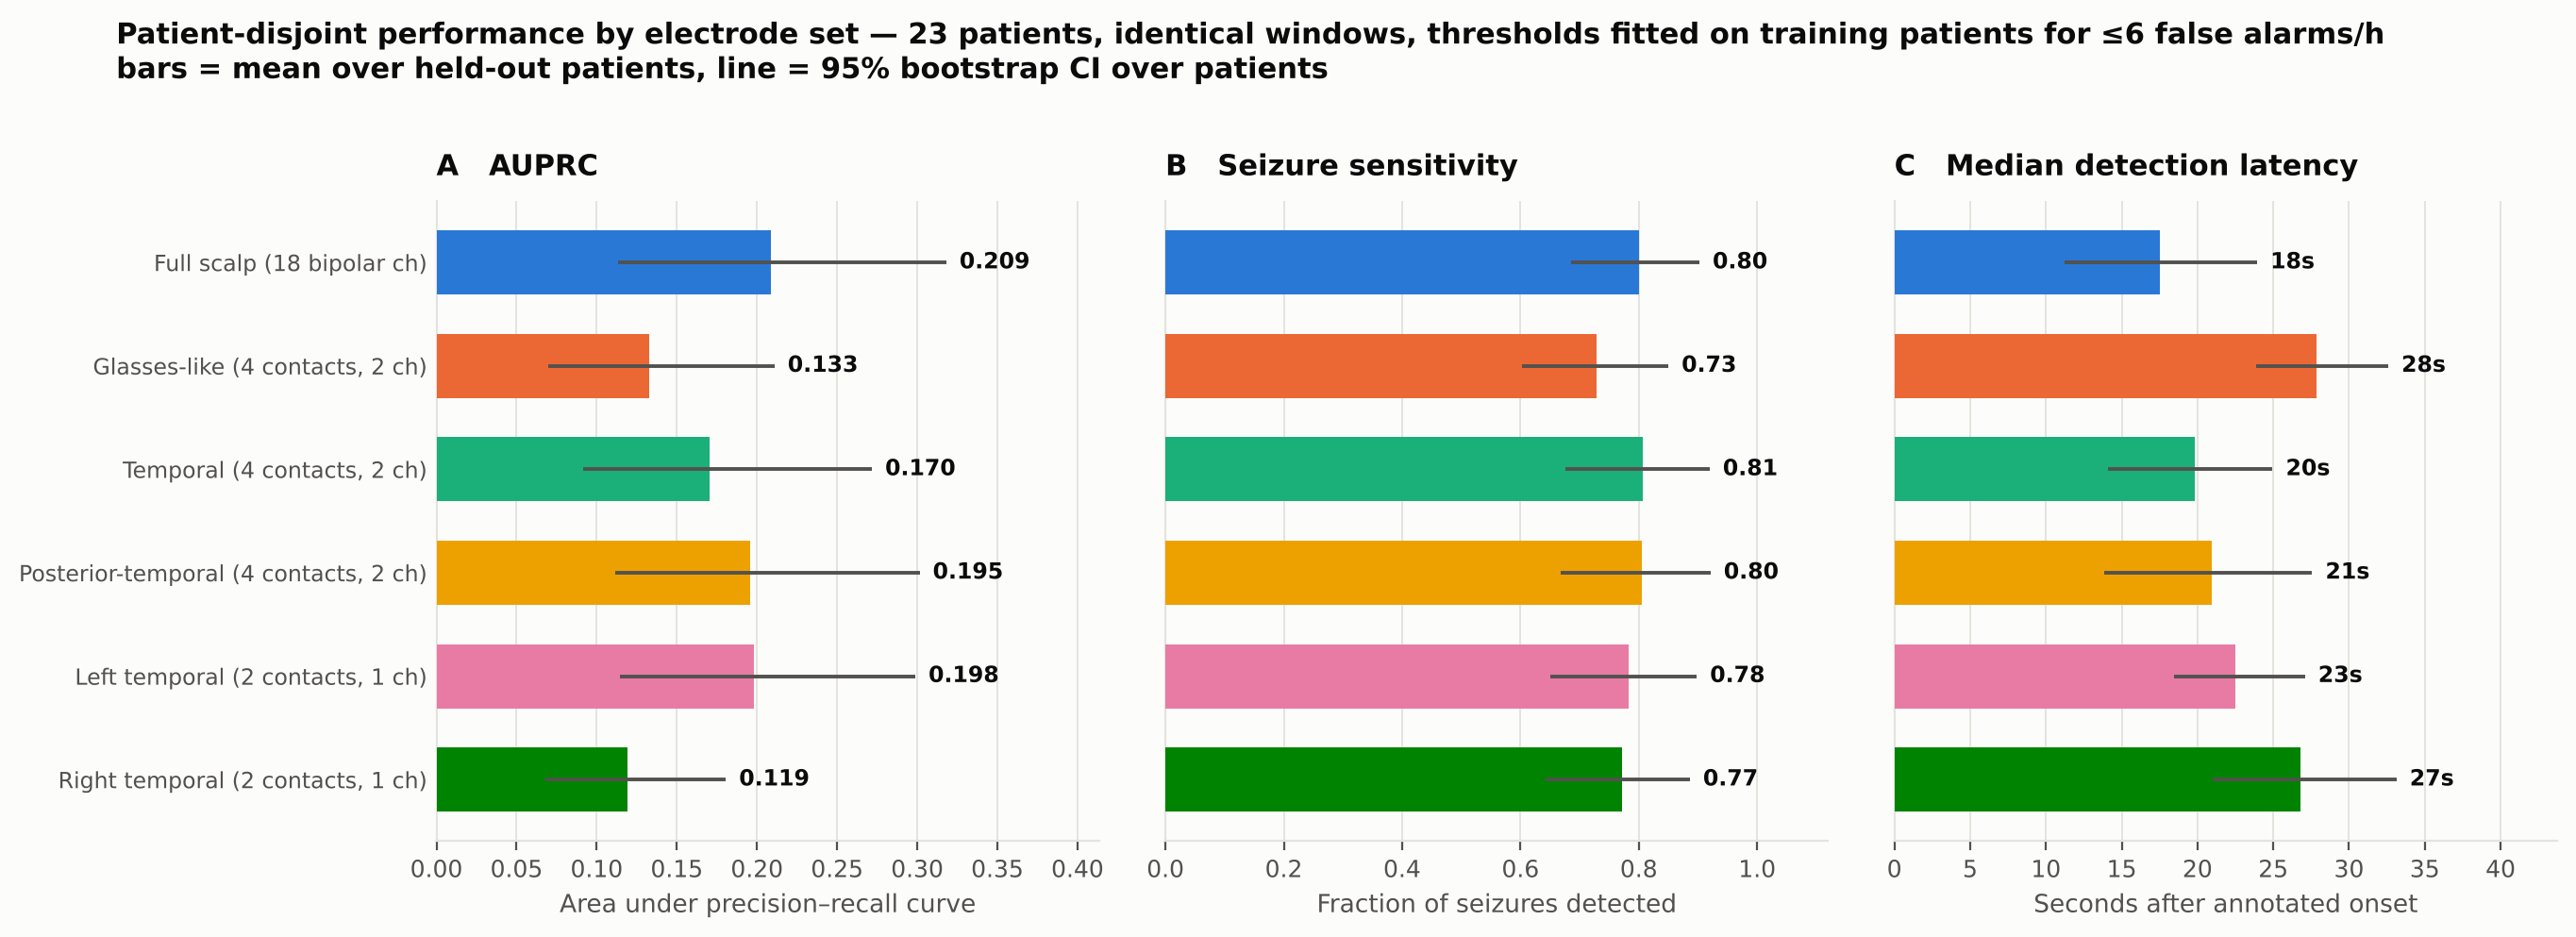

In [7]:
display(Image(filename=str(FIGURES_DIR / "fig2_montage_performance.png")))

### Does the trade-off hold at other alarm budgets?

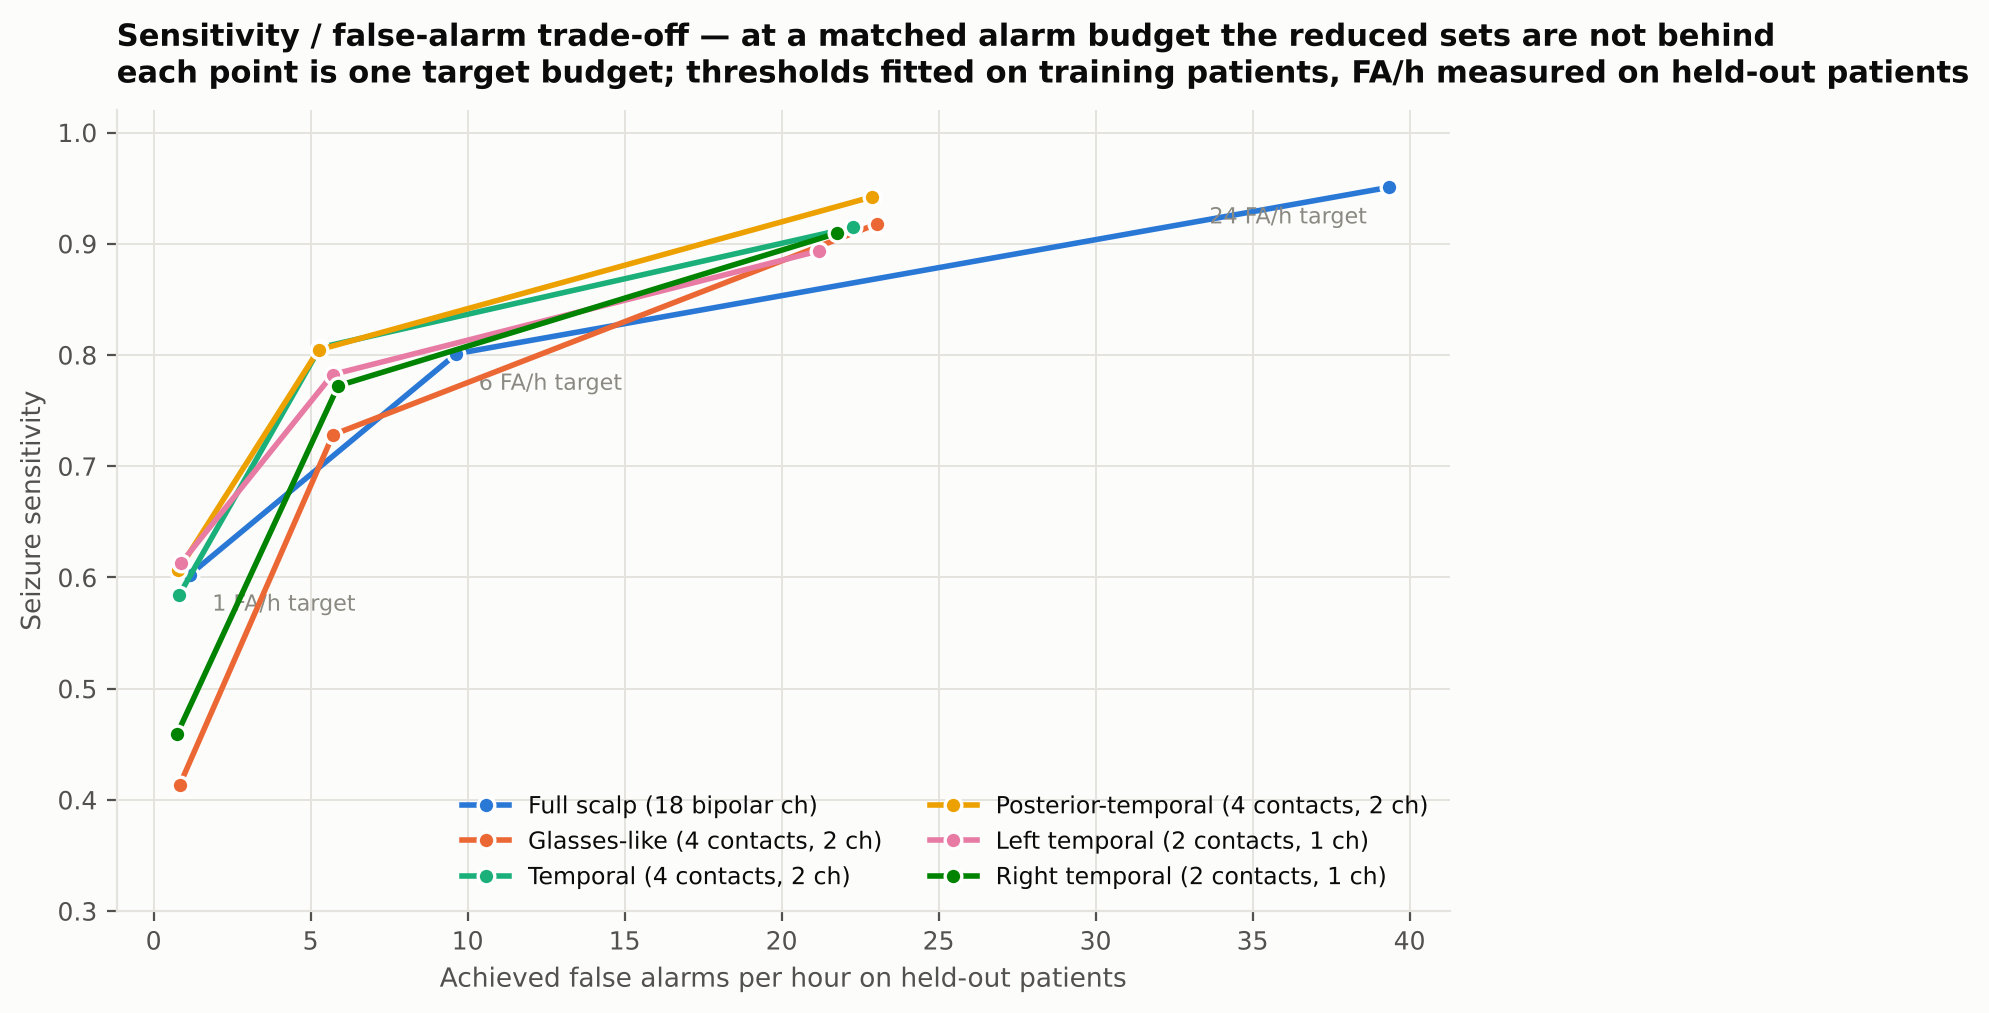

In [8]:
display(Image(filename=str(FIGURES_DIR / "fig3_sensitivity_vs_false_alarms.png")))

### Paired per-patient differences against the full montage

A paired comparison is the honest one here: the same patients, the same windows,
one configuration against another.

In [9]:
d = report.paired_delta(patients, "auprc", 6.0)
display(d[["montage", "n_patients", "mean_delta", "ci_lo", "ci_hi",
           "n_better", "n_worse"]])

,montage,n_patients,mean_delta,ci_lo,ci_hi,n_better,n_worse
0,glasses_4_contacts,23,-0.075976,-0.154255,-0.002378,9,14
1,left_temporal_2_contacts,23,-0.010677,-0.068668,0.045381,11,12
2,posterior_temporal_4_contacts,23,-0.013493,-0.068819,0.036164,14,9
3,right_temporal_2_contacts,23,-0.089912,-0.172272,-0.014813,7,16
4,temporal_4_contacts,23,-0.038551,-0.102015,0.018760,11,12


## 6. Placement control

Every 2-channel subset of the standard 18 derivations, scored the same way. This
puts the wearable-plausible placements on a percentile instead of comparing them
only to each other.

In [10]:
ctrl_path = TABLES_DIR / "random_pair_control.csv"
if ctrl_path.exists():
    ctrl = pd.read_csv(ctrl_path)
    print(f"{len(ctrl)} channel pairs evaluated")
    display(ctrl.head(10))
    for name, key in [("Temporal", "F7-T7+F8-T8"),
                      ("Glasses-like", "FP1-F7+FP2-F8"),
                      ("Posterior-temporal", "T7-P7+T8-P8")]:
        row = ctrl[ctrl.channels == key]
        if not row.empty:
            v = float(row.auprc.iloc[0])
            print(f"{name:20s} AUPRC {v:.3f} - {100*(ctrl.auprc < v).mean():.0f}th percentile")
    display(Image(filename=str(FIGURES_DIR / "fig4_placement_control.png")))
else:
    print("run: python scripts/06_experiments.py random")

run: python scripts/06_experiments.py random


## 7. Per-patient variability

The spread between patients is much larger than the spread between electrode
sets — which is the main practical message for a wearable.

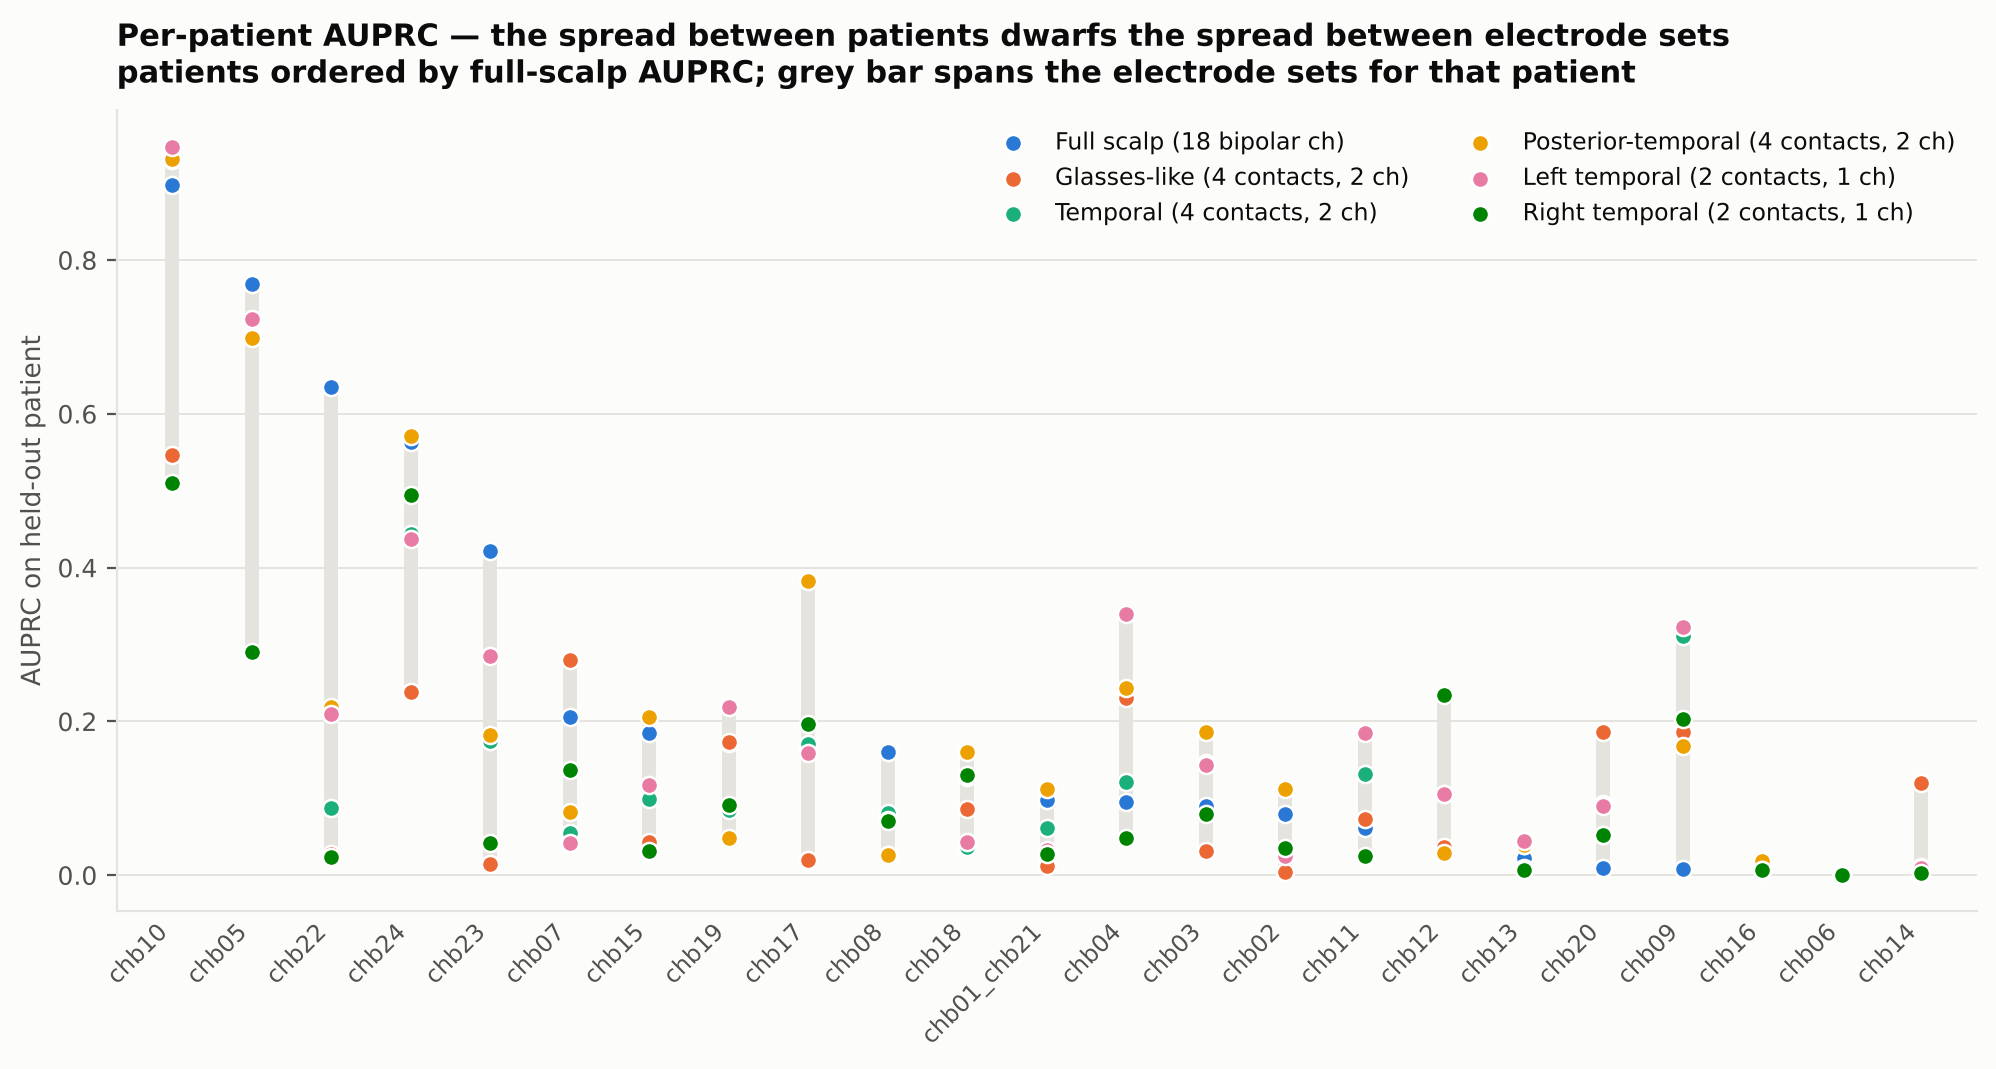

montage,full_18_bipolar,glasses_4_contacts,left_temporal_2_contacts,posterior_temporal_4_contacts,right_temporal_2_contacts,temporal_4_contacts
patient_id,,,,,,
chb01_chb21,0.098,0.012,0.032,0.112,0.028,0.062
chb02,0.079,0.005,0.025,0.113,0.035,0.029
chb03,0.090,0.032,0.143,0.186,0.079,0.146
chb04,0.095,0.231,0.340,0.243,0.048,0.121
chb05,0.768,0.705,0.723,0.698,0.291,0.701
chb06,0.002,0.001,0.001,0.001,0.001,0.001
chb07,0.206,0.280,0.042,0.082,0.137,0.054
chb08,0.160,0.026,0.071,0.027,0.071,0.081
chb09,0.008,0.186,0.323,0.168,0.203,0.311


In [11]:
display(Image(filename=str(FIGURES_DIR / "fig5_per_patient.png")))
pp = (patients[patients.target_fa_per_h == 6.0]
      .pivot_table(index="patient_id", columns="montage", values="auprc"))
display(pp.round(3))

## Caveats

* CHB-MIT is paediatric, single-centre, and these are **scalp-position proxies**
  for wearables, not real device recordings.
* The task is ictal vs non-ictal classification, not seizure prediction.
* CHB-MIT has no seizure-onset-localisation labels, so the "are around-ear
  contacts better for temporal-lobe seizures?" question needs SeizeIT2.
* SeizeIT2's public release has behind-the-ear wearable signals and clinical
  annotations but **no paired full-scalp EEG**, so it supports external
  validation, not a same-recording electrode ablation.